# Tuần 07 — Thực hành k-Means: 3 bài

Demo `03_Demo-kMeans.ipynb` gom cụm bằng tay trên dữ liệu giả 2 chiều.

File này có **3 bài**. Mỗi bài là một bộ dữ liệu thật trên Kaggle. Cả 3 bài đều làm. Dùng `sklearn.cluster.KMeans`.

Clustering không chia train/test và không có nhãn để học. `StandardScaler` fit trên toàn bộ bảng feature. Không đưa cột ID hay tên vào khoảng cách.

Tải 3 file vào `data/`:

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Mall Customer Segmentation | https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python | `data/Mall_Customers.csv` |
| 2 | Unsupervised Learning on Country Data | https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data | `data/Country-data.csv` |
| 3 | Wholesale Customers | https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set | `data/Wholesale customers data.csv` |

Ba bộ này cũng được dùng ở `09_TH-DBSCAN.ipynb`, để so sánh hai cách gom cụm trên cùng dữ liệu.


**Cách chạy:** giải nén notebook và thư mục `data/` cùng nơi, mở notebook rồi chọn Run All. Cần môi trường có numpy, pandas, matplotlib và scikit-learn. Các câu trả lời cuối mỗi bài được in từ số liệu vừa tính. Silhouette ở câu Age là tiêu chí bổ sung để so sánh K; elbow không luôn có một đáp án duy nhất.


In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)


In [2]:
# Nếu giải nén gói đầy đủ, ba CSV đã nằm trong data/ và không cần Internet.
# Nếu chỉ tải notebook, tự tải đúng CSV còn thiếu từ Kaggle (không xóa data/).
from pathlib import Path
import urllib.request
import zipfile
import io

def dam_bao_du_lieu(handle, filename):
    dest = Path('data') / filename
    if not dest.exists():
        print('Đang tải:', filename)
        url = 'https://www.kaggle.com/api/v1/datasets/download/' + handle
        with urllib.request.urlopen(url, timeout=120) as response:
            data_zip = response.read()
        with zipfile.ZipFile(io.BytesIO(data_zip)) as archive:
            matches = [f for f in archive.namelist() if Path(f).name == filename]
            if len(matches) != 1:
                raise ValueError(f'Không tìm thấy duy nhất {filename} trong dữ liệu tải về.')
            dest.parent.mkdir(parents=True, exist_ok=True)
            dest.write_bytes(archive.read(matches[0]))
    print('Sẵn sàng:', dest)

dam_bao_du_lieu('vjchoudhary7/customer-segmentation-tutorial-in-python', 'Mall_Customers.csv')
dam_bao_du_lieu('rohan0301/unsupervised-learning-on-country-data', 'Country-data.csv')
dam_bao_du_lieu('binovi/wholesale-customers-data-set', 'Wholesale customers data.csv')


Sẵn sàng: data/Mall_Customers.csv
Sẵn sàng: data/Country-data.csv
Sẵn sàng: data/Wholesale customers data.csv


## Phần chung

Elbow: với mỗi `K` từ 1 đến `k_max`, fit `KMeans` (`n_init=10`, `random_state=3000`), lưu `inertia_`, rồi vẽ. Chỗ khuỷu tay là `K` nên thử.

Sau khi có nhãn, bảng trung bình theo cụm giúp đọc ý nghĩa từng nhóm.


In [3]:
def ve_elbow(X_scaled, k_max=10):
    ks = list(range(1, k_max + 1))
    inertias = []
    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=3000)
        model.fit(X_scaled)
        inertias.append(model.inertia_)
    print(pd.DataFrame({'K': ks, 'inertia': inertias}).round(2).to_string(index=False))
    plt.figure(figsize=(6, 4))
    plt.plot(ks, inertias, marker='o')
    plt.title('Elbow: inertia theo số cụm K')
    plt.xlabel('K')
    plt.ylabel('Inertia (tổng bình phương khoảng cách đến tâm)')
    plt.xticks(ks)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
    return ks, inertias


def bang_trung_binh(df_goc, labels, cot_so):
    tam = df_goc[cot_so].copy()
    tam['cum'] = labels
    return tam.groupby('cum').mean().round(2)


---

# Bài 1 — Khách hàng trung tâm thương mại

Nguồn: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

200 khách. Cột: `CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`.

Bài này chỉ dùng **thu nhập** và **điểm chi tiêu**. Bỏ `CustomerID`. Không đưa `Gender` vào khoảng cách. Có thể để `Age` sang một lần chạy riêng nếu còn thời gian.

Chuẩn hóa hai cột, vẽ elbow, chọn `K`, tô màu scatter theo cụm. Dấu `x` là tâm cụm tính trên **số gốc** (trung bình thu nhập và điểm chi tiêu của các điểm trong cụm), để đọc được đơn vị thật.


 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40
Kích thước: (200, 5)
 K  inertia
 1   400.00
 2   270.67
 3   157.70
 4   108.92
 5    65.57
 6    55.10
 7    44.87
 8    37.18
 9    32.38
10    29.08


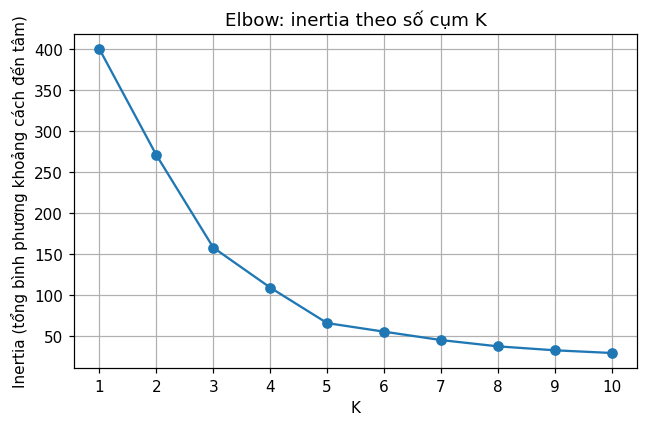

In [4]:
mall = pd.read_csv('data/Mall_Customers.csv')
print(mall.head().to_string(index=False))
print('Kích thước:', mall.shape)
cot = ['Annual Income (k$)', 'Spending Score (1-100)']
X = mall[cot].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)
ks_mall, inertia_mall = ve_elbow(X_scaled)


     Annual Income (k$)  Spending Score (1-100)
cum                                            
0                 55.30                   49.52
1                 88.20                   17.11
2                 26.30                   20.91
3                 86.54                   82.13
4                 25.73                   79.36
Số điểm mỗi cụm: (array([0, 1, 2, 3, 4], dtype=int32), array([81, 35, 23, 39, 22]))


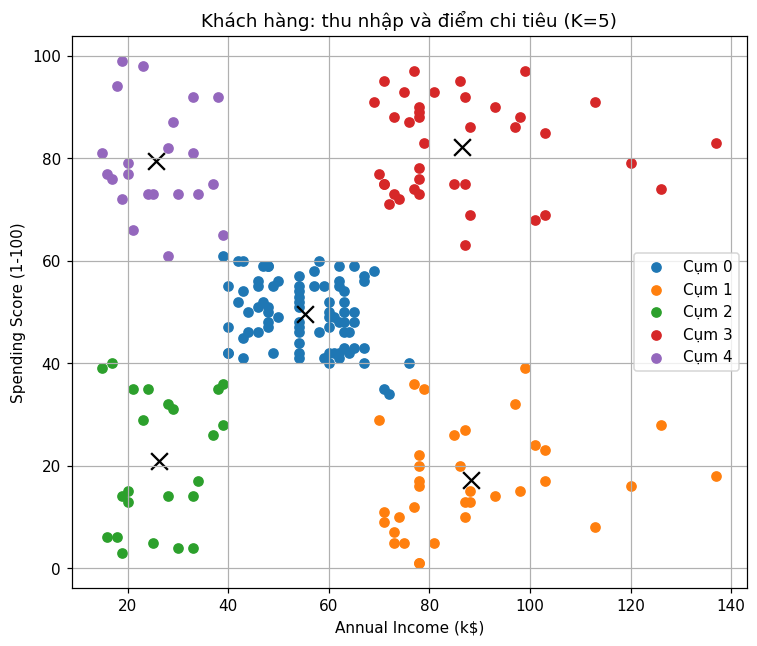

In [5]:
# Elbow và scatter gợi ý 5 nhóm thu nhập - chi tiêu.
K = 5
K_mall = K
model = KMeans(n_clusters=K, n_init=10, random_state=3000)
labels = model.fit_predict(X_scaled)
labels_mall = labels.copy()
plt.figure(figsize=(7, 6))
for cum in np.unique(labels):
    pts = X[labels == cum]
    plt.scatter(pts[:, 0], pts[:, 1], label=f'Cụm {cum}')
    plt.scatter(pts[:, 0].mean(), pts[:, 1].mean(), c='black', marker='x', s=120)
plt.title('Khách hàng: thu nhập và điểm chi tiêu (K=5)')
plt.xlabel(cot[0]); plt.ylabel(cot[1])
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
tb_mall = bang_trung_binh(mall, labels, cot)
print(tb_mall.to_string())
print('Số điểm mỗi cụm:', np.unique(labels, return_counts=True))


**Nộp kèm bài 1**

1. `K` bạn chọn là bao nhiêu? Elbow gãy ở đâu?
2. Mô tả từng cụm bằng thu nhập và điểm chi tiêu (cao / thấp). Cụm nào đáng ưu tiên cho khuyến mãi?
3. Nếu thêm cột `Age` vào `X` rồi chuẩn hóa lại, bạn có đổi `K` không?


1. Chọn K=5: đường elbow giảm nhanh trước khoảng K=5 và giảm chậm hơn sau đó.
   Đây là lựa chọn diễn giải được, không phải chứng minh K tối ưu duy nhất.
2. Mô tả từng cụm (cao/thấp so với trung bình toàn bộ khách hàng):
Cụm 0: thu nhập 55.30 k$ (thấp), điểm chi tiêu 49.52 (thấp).
Cụm 1: thu nhập 88.20 k$ (cao), điểm chi tiêu 17.11 (thấp).
Cụm 2: thu nhập 26.30 k$ (thấp), điểm chi tiêu 20.91 (thấp).
Cụm 3: thu nhập 86.54 k$ (cao), điểm chi tiêu 82.13 (cao).
Cụm 4: thu nhập 25.73 k$ (thấp), điểm chi tiêu 79.36 (cao).
Cụm 0 nằm gần mức trung bình tổng thể nhất, có thể gọi là nhóm trung bình.
Ưu tiên chương trình giữ chân/khách hàng thân thiết cho nhóm thu nhập cao, chi tiêu cao: [3]
Nhóm thu nhập cao nhưng chi tiêu thấp có thể thử ưu đãi để tăng mua; cần thử nghiệm để biết hiệu quả.
 K  inertia
 1   600.00
 2   389.39
 3   295.50
 4   205.23
 5   168.25
 6   133.87
 7   117.13
 8   103.85
 9    92.01
10    81.84
So sánh khi thêm Age (silhouette càng cao càng tốt):
 K  silhouette
 2      

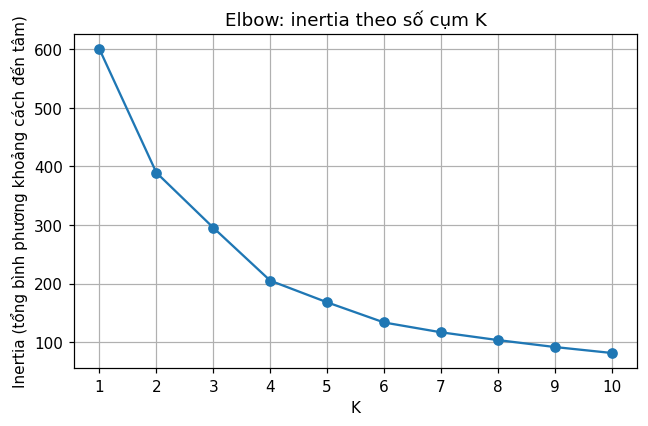

In [6]:
print('1. Chọn K=5: đường elbow giảm nhanh trước khoảng K=5 và giảm chậm hơn sau đó.')
print('   Đây là lựa chọn diễn giải được, không phải chứng minh K tối ưu duy nhất.')
print('2. Mô tả từng cụm (cao/thấp so với trung bình toàn bộ khách hàng):')
nguong = mall[cot].mean()
for cum, row in tb_mall.iterrows():
    thu_nhap = 'cao' if row[cot[0]] >= nguong[cot[0]] else 'thấp'
    chi_tieu = 'cao' if row[cot[1]] >= nguong[cot[1]] else 'thấp'
    print(f"Cụm {cum}: thu nhập {row[cot[0]]:.2f} k$ ({thu_nhap}), "
          f"điểm chi tiêu {row[cot[1]]:.2f} ({chi_tieu}).")
nhom_trung_tam = ((tb_mall - nguong) / mall[cot].std()).pow(2).sum(axis=1).idxmin()
print(f'Cụm {nhom_trung_tam} nằm gần mức trung bình tổng thể nhất, có thể gọi là nhóm trung bình.')
nhom_uu_tien = tb_mall[(tb_mall[cot[0]] >= nguong[cot[0]]) &
                      (tb_mall[cot[1]] >= nguong[cot[1]])].index.tolist()
print('Ưu tiên chương trình giữ chân/khách hàng thân thiết cho nhóm thu nhập cao, chi tiêu cao:', nhom_uu_tien)
print('Nhóm thu nhập cao nhưng chi tiêu thấp có thể thử ưu đãi để tăng mua; cần thử nghiệm để biết hiệu quả.')

# Thực sự chạy thêm Age để trả lời câu 3, thay vì đoán.
from sklearn.metrics import silhouette_score
cot_age = ['Age'] + cot
X_age = StandardScaler().fit_transform(mall[cot_age].to_numpy(dtype=float))
ks_age, inertia_age = ve_elbow(X_age)
ket_qua_age = []
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=10, random_state=3000).fit_predict(X_age)
    ket_qua_age.append((k, silhouette_score(X_age, lab)))
bang_age = pd.DataFrame(ket_qua_age, columns=['K', 'silhouette'])
print('So sánh khi thêm Age (silhouette càng cao càng tốt):')
print(bang_age.round(4).to_string(index=False))
k_age = int(bang_age.loc[bang_age['silhouette'].idxmax(), 'K'])
print(f'3. Nếu bổ sung tiêu chí silhouette trong K=2..10, chọn K={k_age} khi thêm Age.')
print('Có đổi K so với hai đặc trưng không?', 'Có.' if k_age != K_mall else 'Không.')
print('Thêm tuổi làm thay đổi khoảng cách giữa khách hàng; phải đánh giá lại K, không mặc định giữ K cũ.')


---

# Bài 2 — Phân nhóm quốc gia

Nguồn: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data

167 nước, file `Country-data.csv`. Cột `country` là tên, không đưa vào `X`.

Các cột số: `child_mort`, `exports`, `health`, `imports`, `income`, `inflation`, `life_expec`, `total_fer`, `gdpp`.

`income` và `gdpp` lớn hơn `child_mort` rất nhiều. Bắt buộc `StandardScaler`. Chọn `K` bằng elbow (thường thử quanh 3). In trung bình `child_mort`, `income`, `life_expec`, `gdpp` theo cụm, và liệt kê khoảng 8 tên nước mỗi cụm.


            country  child_mort  exports  health  imports  income  inflation  life_expec  total_fer  gdpp
        Afghanistan        90.2     10.0    7.58     44.9    1610       9.44        56.2       5.82   553
            Albania        16.6     28.0    6.55     48.6    9930       4.49        76.3       1.65  4090
            Algeria        27.3     38.4    4.17     31.4   12900      16.10        76.5       2.89  4460
             Angola       119.0     62.3    2.85     42.9    5900      22.40        60.1       6.16  3530
Antigua and Barbuda        10.3     45.5    6.03     58.9   19100       1.44        76.8       2.13 12200
Kích thước: (167, 10)
 K  inertia
 1  1503.00
 2  1050.21
 3   831.42
 4   700.39
 5   620.45
 6   572.09
 7   503.09
 8   451.32
 9   425.21
10   394.57


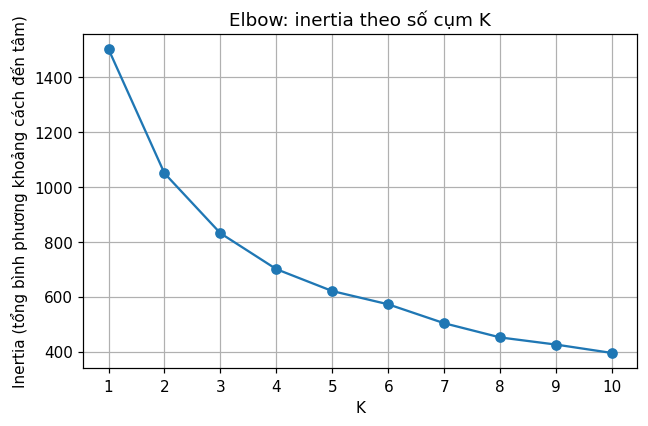

In [7]:
country = pd.read_csv('data/Country-data.csv')
print(country.head().to_string(index=False))
print('Kích thước:', country.shape)
cot_so = [c for c in country.columns if c != 'country']
X_country = country[cot_so].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X_country)
ks_country, inertia_country = ve_elbow(X_scaled)


In [8]:
# Chọn K=3 để phân biệt ba nhóm có điều kiện phát triển khác nhau.
K = 3
labels = KMeans(n_clusters=K, n_init=10, random_state=3000).fit_predict(X_scaled)
labels_country = labels.copy()
tb_country = bang_trung_binh(country, labels, ['child_mort', 'income', 'life_expec', 'gdpp'])
print(tb_country.to_string())
for cum in np.unique(labels):
    ten = country.loc[labels == cum, 'country'].head(8).tolist()
    print(f'Cụm {cum} ({np.sum(labels == cum)} nước):', ten)


     child_mort    income  life_expec      gdpp
cum                                            
0         21.93  12305.60       72.81   6486.45
1         92.96   3942.40       59.19   1922.38
2          5.00  45672.22       80.13  42494.44
Cụm 0 (84 nước): ['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahamas', 'Bangladesh']
Cụm 1 (47 nước): ['Afghanistan', 'Angola', 'Benin', 'Botswana', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic']
Cụm 2 (36 nước): ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Czech Republic']


**Nộp kèm bài 2**

1. `K` bạn chọn? Cụm nào có `child_mort` cao và `gdpp` thấp?
2. Kể tên 3 nước thuộc cụm đó và 3 nước thuộc cụm có `gdpp` cao.
3. Vì sao không chuẩn hóa thì `income` và `gdpp` sẽ át các cột còn lại?


In [9]:
cum_child_cao = tb_country['child_mort'].idxmax()
cum_gdpp_thap = tb_country['gdpp'].idxmin()
cum_gdpp_cao = tb_country['gdpp'].idxmax()
print('1. Chọn K=3, theo vùng khuỷu tay khoảng 3 và khả năng diễn giải các nhóm.')
print(f'Cụm {cum_child_cao} có child_mort cao nhất: {tb_country.loc[cum_child_cao, "child_mort"]:.2f}.')
print(f'Cụm {cum_gdpp_thap} có gdpp thấp nhất: {tb_country.loc[cum_gdpp_thap, "gdpp"]:.2f}.')
if cum_child_cao == cum_gdpp_thap:
    print(f'Vậy cụm {cum_child_cao} đồng thời có child_mort cao và gdpp thấp.')
print('2. Ba nước trong cụm child_mort cao:', country.loc[labels_country == cum_child_cao, 'country'].head(3).tolist())
print('Ba nước trong cụm gdpp cao:', country.loc[labels_country == cum_gdpp_cao, 'country'].head(3).tolist())
print('3. Khoảng cách Euclid bình phương độ chênh từng đặc trưng rồi cộng lại. '
      'income và gdpp có độ lớn/độ phân tán lớn nên dễ chi phối khoảng cách nếu dùng số gốc. '
      'StandardScaler đưa mỗi cột về trung bình 0, độ lệch chuẩn 1 (với cột có biến thiên), '
      'giúp so sánh trên thang đo tương đương.')
print('Tên/số cụm chỉ là mã nhóm; không phải thứ hạng. Kết quả là mô tả dữ liệu, không kết luận nguyên nhân.')


1. Chọn K=3, theo vùng khuỷu tay khoảng 3 và khả năng diễn giải các nhóm.
Cụm 1 có child_mort cao nhất: 92.96.
Cụm 1 có gdpp thấp nhất: 1922.38.
Vậy cụm 1 đồng thời có child_mort cao và gdpp thấp.
2. Ba nước trong cụm child_mort cao: ['Afghanistan', 'Angola', 'Benin']
Ba nước trong cụm gdpp cao: ['Australia', 'Austria', 'Bahrain']
3. Khoảng cách Euclid bình phương độ chênh từng đặc trưng rồi cộng lại. income và gdpp có độ lớn/độ phân tán lớn nên dễ chi phối khoảng cách nếu dùng số gốc. StandardScaler đưa mỗi cột về trung bình 0, độ lệch chuẩn 1 (với cột có biến thiên), giúp so sánh trên thang đo tương đương.
Tên/số cụm chỉ là mã nhóm; không phải thứ hạng. Kết quả là mô tả dữ liệu, không kết luận nguyên nhân.


---

# Bài 3 — Khách sỉ

Nguồn: https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set

440 khách hàng bán sỉ. File `Wholesale customers data.csv`.

Cột: `Channel`, `Region`, `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.

`Channel` (1 = Horeca, 2 = Retail) và `Region` là mã nhóm, không phải số tiền. **Không** đưa hai cột này vào `X`. Gom cụm trên 6 cột chi tiêu, sau chuẩn hóa. Rồi dùng `pd.crosstab` để xem mỗi cụm nằm ở kênh nào.


 Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
       2       3  12669  9656     7561     214              2674        1338
       2       3   7057  9810     9568    1762              3293        1776
       2       3   6353  8808     7684    2405              3516        7844
       1       3  13265  1196     4221    6404               507        1788
       2       3  22615  5410     7198    3915              1777        5185
Kích thước: (440, 8)
 K  inertia
 1  2640.00
 2  1954.18
 3  1619.95
 4  1313.76
 5  1058.77
 6   917.45
 7   825.84
 8   751.74
 9   666.22
10   594.86


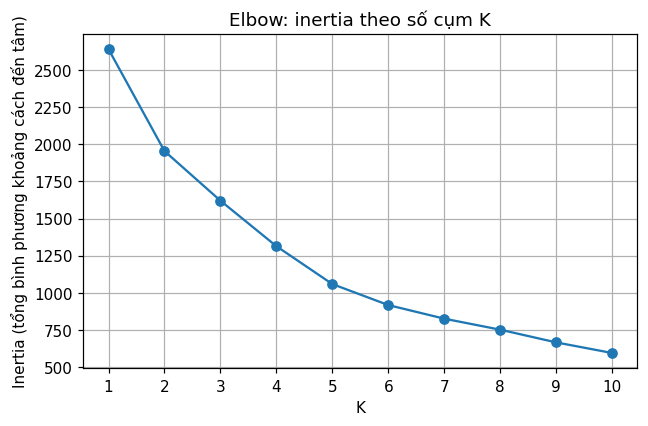

In [10]:
ws = pd.read_csv('data/Wholesale customers data.csv')
print(ws.head().to_string(index=False))
print('Kích thước:', ws.shape)
cot_chi = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X_ws = ws[cot_chi].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X_ws)
ks_ws, inertia_ws = ve_elbow(X_scaled)


In [11]:
# Chọn K=5: sau khoảng K=5, mức giảm inertia nhỏ hơn.
K = 5
labels = KMeans(n_clusters=K, n_init=10, random_state=3000).fit_predict(X_scaled)
labels_ws = labels.copy()
tb_ws = bang_trung_binh(ws, labels, cot_chi)
kenh_ws = pd.crosstab(labels, ws['Channel'], rownames=['cum'], colnames=['Channel'])
print(tb_ws.to_string())
print('Số khách mỗi cụm:', np.unique(labels, return_counts=True))
print(kenh_ws.to_string())


        Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
cum                                                                      
0    32957.98   4997.35   5884.76   8422.84            954.60     2462.97
1    36847.00  43950.00  20170.00  36534.00            239.00    47943.00
2    15964.90  34708.50  48536.90   3054.60          24875.20     2942.80
3     5754.17  10866.60  16607.10   1464.12           7202.88     1813.39
4     9092.16   2967.76   3807.41   2271.76            989.81      978.96
Số khách mỗi cụm: (array([0, 1, 2, 3, 4], dtype=int32), array([ 63,   1,  10,  96, 270]))
Channel    1   2
cum             
0         55   8
1          1   0
2          0  10
3          9  87
4        233  37


**Nộp kèm bài 3**

1. `K` bạn chọn? Cụm nào chi mạnh cho `Grocery` và `Detergents_Paper`?
2. Cụm đó lệch về `Channel` nào trên bảng crosstab?
3. So với bài 1: vì sao bài 3 không vẽ một scatter là đủ để đọc cụm?


In [12]:
# So sánh cả hai khoản chi; chuẩn hóa trung bình cụm trước khi cộng để tránh lệch đơn vị.
chi_can_xet = ['Grocery', 'Detergents_Paper']
diem_chi = ((tb_ws[chi_can_xet] - ws[chi_can_xet].mean()) /
            ws[chi_can_xet].std(ddof=0)).mean(axis=1)
cum_chi_manh = diem_chi.idxmax()
print('1. Chọn K=5: đường elbow bắt đầu phẳng hơn sau khoảng 5; điểm gãy không hoàn toàn rõ.')
print('Đây là lựa chọn thực hành có thể diễn giải; không khẳng định K=5 tối ưu duy nhất.')
print(f'Cụm {cum_chi_manh} có mức chi tổng hợp Grocery và Detergents_Paper cao nhất:')
print(tb_ws.loc[[cum_chi_manh], chi_can_xet].to_string())
print('Cụm cao nhất riêng Grocery:', tb_ws['Grocery'].idxmax())
print('Cụm cao nhất riêng Detergents_Paper:', tb_ws['Detergents_Paper'].idxmax())
so_kenh = kenh_ws.loc[cum_chi_manh]
kenh_dong = so_kenh[so_kenh == so_kenh.max()].index.tolist()
ten_kenh = {1: 'Horeca', 2: 'Retail'}
print('2. Phân bố Channel trong cụm:')
print(so_kenh.to_string())
for kenh in kenh_dong:
    print(f'Channel {kenh} ({ten_kenh.get(kenh, "khác")}): '
          f'{so_kenh[kenh]} khách, chiếm {so_kenh[kenh]/so_kenh.sum():.2%}.')
if len(kenh_dong) > 1:
    print('Các kênh đồng số lượng, không có kênh chiếm ưu thế duy nhất.')
print('3. Bài 1 dùng hai feature nên scatter 2D biểu diễn đầy đủ không gian phân cụm. '
      'Bài 3 dùng sáu feature: một scatter 2D chỉ cho thấy hai chiều và có thể che mất khác biệt. '
      'Cần đọc bảng trung bình, nhiều cặp biểu đồ hoặc PCA 2D (có mất thông tin).')
print('Channel và Region chỉ dùng mô tả sau phân cụm, không đưa vào khoảng cách.')
print('Lưu ý: cụm ít điểm có thể phản ánh khách hàng ngoại lệ; cần đọc số lượng trước khi kết luận phân khúc.')


1. Chọn K=5: đường elbow bắt đầu phẳng hơn sau khoảng 5; điểm gãy không hoàn toàn rõ.
Đây là lựa chọn thực hành có thể diễn giải; không khẳng định K=5 tối ưu duy nhất.
Cụm 2 có mức chi tổng hợp Grocery và Detergents_Paper cao nhất:
     Grocery  Detergents_Paper
cum                           
2    48536.9           24875.2
Cụm cao nhất riêng Grocery: 2
Cụm cao nhất riêng Detergents_Paper: 2
2. Phân bố Channel trong cụm:
Channel
1     0
2    10
Channel 2 (Retail): 10 khách, chiếm 100.00%.
3. Bài 1 dùng hai feature nên scatter 2D biểu diễn đầy đủ không gian phân cụm. Bài 3 dùng sáu feature: một scatter 2D chỉ cho thấy hai chiều và có thể che mất khác biệt. Cần đọc bảng trung bình, nhiều cặp biểu đồ hoặc PCA 2D (có mất thông tin).
Channel và Region chỉ dùng mô tả sau phân cụm, không đưa vào khoảng cách.
Lưu ý: cụm ít điểm có thể phản ánh khách hàng ngoại lệ; cần đọc số lượng trước khi kết luận phân khúc.
